In [1]:
import pandas as pd

# Load overall model summaries
ed_df = pd.read_csv("energy_detector_results.csv")
lr_df = pd.read_csv("logistic_regression_summary.csv")
rf_df = pd.read_csv("random_forest_summary.csv")

print("Energy Detection columns:")
print(ed_df.columns.tolist())

print("\nLogistic Regression columns:")
print(lr_df.columns.tolist())

print("\nRandom Forest columns:")
print(rf_df.columns.tolist())

Energy Detection columns:
['SNR', 'Pd', 'Pfa', 'Pm']

Logistic Regression columns:
['Accuracy', 'Pd', 'Pfa', 'Pm', 'ROC_AUC']

Random Forest columns:
['Model', 'Threshold', 'Accuracy', 'Pd', 'Pfa', 'Pm', 'ROC_AUC']


In [2]:
import pandas as pd

# Load model summaries
lr_df = pd.read_csv("logistic_regression_summary.csv")
rf_df = pd.read_csv("random_forest_summary.csv")

# Create overall comparison table
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_df.loc[0, "Accuracy"],
        "Pd": lr_df.loc[0, "Pd"],
        "Pfa": lr_df.loc[0, "Pfa"],
        "Pm": lr_df.loc[0, "Pm"],
        "ROC_AUC": lr_df.loc[0, "ROC_AUC"]
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_df.loc[0, "Accuracy"],
        "Pd": rf_df.loc[0, "Pd"],
        "Pfa": rf_df.loc[0, "Pfa"],
        "Pm": rf_df.loc[0, "Pm"],
        "ROC_AUC": rf_df.loc[0, "ROC_AUC"]
    }
])

print(comparison_df.round(4))

                 Model  Accuracy      Pd     Pfa      Pm  ROC_AUC
0  Logistic Regression    0.6719  0.3838  0.0400  0.6162   0.8314
1        Random Forest    0.8219  0.6990  0.0552  0.3010   0.9383


In [15]:
import pandas as pd
import numpy as np

# Reload original model summaries
ed_df = pd.read_csv("energy_detector_results.csv")
lr_df = pd.read_csv("logistic_regression_summary.csv")
rf_df = pd.read_csv("random_forest_summary.csv")

# Calculate overall Energy Detection metrics
samples_per_class = 150
n_snr = len(ed_df)

total_tp = round(ed_df["Pd"].sum() * samples_per_class)
total_fp = round(ed_df["Pfa"].sum() * samples_per_class)
total_fn = round(ed_df["Pm"].sum() * samples_per_class)
total_tn = n_snr * samples_per_class - total_fp

ed_summary = {
    "Model": "Energy Detection",
    "Accuracy": (total_tp + total_tn) / (2 * n_snr * samples_per_class),
    "Pd": total_tp / (total_tp + total_fn),
    "Pfa": total_fp / (total_fp + total_tn),
    "Pm": total_fn / (total_tp + total_fn),
    "ROC_AUC": np.nan
}

# Rebuild comparison table from scratch
comparison_df = pd.DataFrame([
    ed_summary,
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_df.loc[0, "Accuracy"],
        "Pd": lr_df.loc[0, "Pd"],
        "Pfa": lr_df.loc[0, "Pfa"],
        "Pm": lr_df.loc[0, "Pm"],
        "ROC_AUC": lr_df.loc[0, "ROC_AUC"]
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_df.loc[0, "Accuracy"],
        "Pd": rf_df.loc[0, "Pd"],
        "Pfa": rf_df.loc[0, "Pfa"],
        "Pm": rf_df.loc[0, "Pm"],
        "ROC_AUC": rf_df.loc[0, "ROC_AUC"]
    }
])

print(comparison_df.round(4))

comparison_df.to_csv(
    "model_comparison_summary.csv",
    index=False
)

                 Model  Accuracy      Pd     Pfa      Pm  ROC_AUC
0     Energy Detection    0.8024  0.6600  0.0552  0.3400      NaN
1  Logistic Regression    0.6719  0.3838  0.0400  0.6162   0.8314
2        Random Forest    0.8219  0.6990  0.0552  0.3010   0.9383


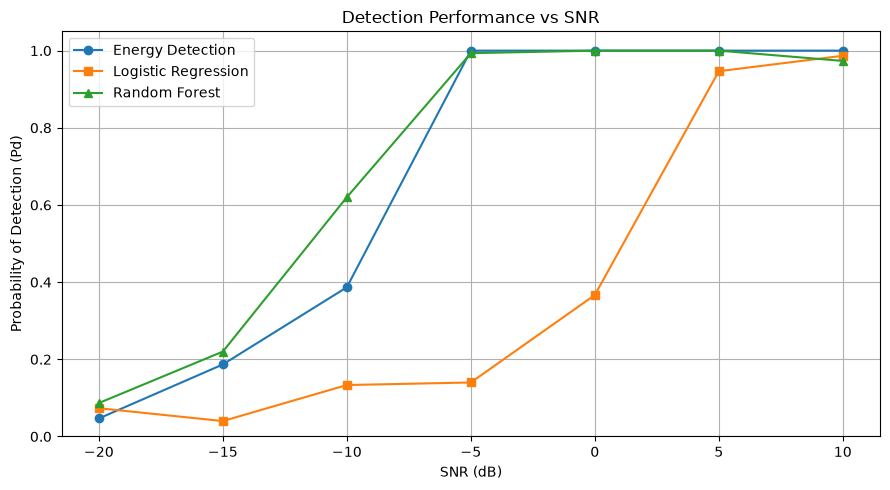

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Load SNR-wise results
ed_results = pd.read_csv("energy_detector_results.csv")
lr_results = pd.read_csv("logistic_regression_results.csv")
rf_results = pd.read_csv("random_forest_results.csv")

# Plot 1: Probability of Detection vs SNR
plt.figure(figsize=(9, 5))

plt.plot(ed_results["SNR"], ed_results["Pd"],
         marker="o", label="Energy Detection")

plt.plot(lr_results["SNR"], lr_results["Pd"],
         marker="s", label="Logistic Regression")

plt.plot(rf_results["SNR"], rf_results["Pd"],
         marker="^", label="Random Forest")

plt.xlabel("SNR (dB)")
plt.ylabel("Probability of Detection (Pd)")
plt.title("Detection Performance vs SNR")
plt.ylim(0, 1.05)
plt.xticks(ed_results["SNR"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("pd_vs_snr.png", dpi=300, bbox_inches="tight")
plt.show()

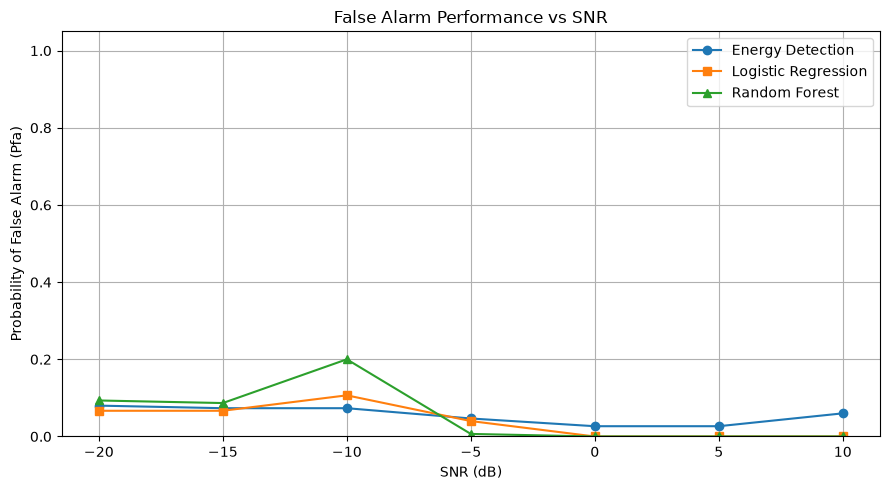

In [21]:
# Plot 2: Probability of False Alarm vs SNR
plt.figure(figsize=(9, 5))

plt.plot(ed_results["SNR"], ed_results["Pfa"],
         marker="o", label="Energy Detection")

plt.plot(lr_results["SNR"], lr_results["Pfa"],
         marker="s", label="Logistic Regression")

plt.plot(rf_results["SNR"], rf_results["Pfa"],
         marker="^", label="Random Forest")

plt.xlabel("SNR (dB)")
plt.ylabel("Probability of False Alarm (Pfa)")
plt.title("False Alarm Performance vs SNR")
plt.ylim(0, 1.05)
plt.xticks(ed_results["SNR"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("pfa_vs_snr.png", dpi=300, bbox_inches="tight")
plt.show()